# Multicolinealidad en la ecuación de salarios de Mincer

**Curso:** Fundamentos de Econometría

**Pregunta:** ¿Cómo afectan la educación, la experiencia y otras características al salario? ¿Qué pasa con nuestras estimaciones cuando los regresores están muy correlacionados?

**Datos:** `wage2` de Wooldridge (*Introductory Econometrics*): 935 hombres trabajadores, *National Longitudinal Survey*, EE. UU., 1980.

**Modelo base (Mincer, 1974):**

$$\ln(w_i) = \beta_0 + \beta_1\, educ_i + \beta_2\, exper_i + \beta_3\, exper_i^2 + u_i$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
import wooldridge

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)

## 1. Datos y estadística descriptiva

In [2]:
df = wooldridge.data("wage2")
vars_ = ["wage", "lwage", "educ", "exper", "tenure", "age", "IQ", "KWW", "meduc", "feduc"]
df = df[vars_ + ["married", "black", "south", "urban"]].dropna().reset_index(drop=True)
print(f"Observaciones después de eliminar faltantes: {len(df)}")
df[vars_].describe().T

Observaciones después de eliminar faltantes: 722


,count,mean,std,min,25%,50%,75%,max
wage,722.0000,977.0983,408.0922,115.0000,684.0000,923.0000,1200.0000,3078.0000
lwage,722.0000,6.7999,0.4194,4.7449,6.5280,6.8276,7.0901,8.0320
educ,722.0000,13.6634,2.2368,9.0000,12.0000,13.0000,16.0000,18.0000
exper,722.0000,11.3338,4.2493,1.0000,8.0000,11.0000,15.0000,22.0000
tenure,722.0000,7.1898,5.0249,0.0000,3.0000,7.0000,11.0000,22.0000
age,722.0000,32.9003,3.0883,28.0000,30.0000,32.0000,36.0000,38.0000
IQ,722.0000,102.1177,14.7718,54.0000,93.0000,103.0000,112.0000,145.0000
KWW,722.0000,35.8753,7.6790,12.0000,31.0000,37.0000,41.0000,56.0000
meduc,722.0000,10.8061,2.8286,0.0000,9.0000,12.0000,12.0000,18.0000
feduc,722.0000,10.2548,3.3058,0.0000,8.0000,10.5000,12.0000,18.0000


**Variables:**
- `wage`: salario mensual (USD 1980); `lwage`: su logaritmo
- `educ`: años de escolaridad; `exper`: años de experiencia; `tenure`: años con el empleador actual; `age`: edad
- `IQ`: coeficiente intelectual; `KWW`: puntaje en una prueba de conocimiento del mundo laboral
- `meduc`, `feduc`: escolaridad de la madre y del padre

## 2. Matriz de correlaciones

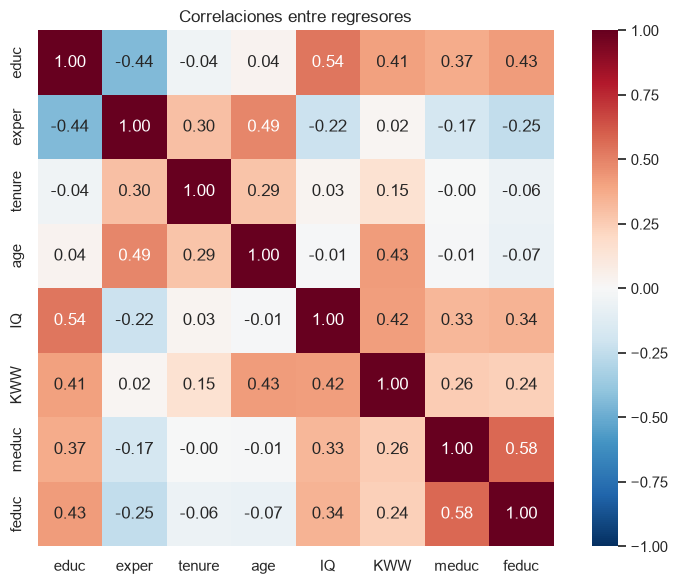

In [3]:
X_vars = ["educ", "exper", "tenure", "age", "IQ", "KWW", "meduc", "feduc"]
corr = df[X_vars].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Correlaciones entre regresores")
plt.tight_layout()
plt.show()

Las correlaciones más altas son de esperarse: `IQ`–`KWW` (dos medidas de habilidad), `meduc`–`feduc` (emparejamiento de los padres) y `educ`–`IQ`. Ninguna por sí sola es extrema, pero **la multicolinealidad puede existir aunque ninguna correlación bivariada sea alta**. Por eso necesitamos el VIF.

## 3. Multicolinealidad **perfecta**: la experiencia potencial

En muchas bases no se observa la experiencia real y se usa la *experiencia potencial*:

$$pexper = age - educ - 6$$

Si incluimos `age`, `educ` y `pexper` en el mismo modelo, una columna es combinación lineal exacta de las otras y la matriz $X'X$ **no es invertible**.

In [4]:
df["pexper"] = df["age"] - df["educ"] - 6
X = sm.add_constant(df[["educ", "age", "pexper"]])
print("Rango de X:", np.linalg.matrix_rank(X.values), "de", X.shape[1], "columnas")
print("Número de condición de X'X: {:.2e}".format(np.linalg.cond(X.T @ X)))

Rango de X: 3 de 4 columnas
Número de condición de X'X: 9.62e+16


In [5]:
# statsmodels usa la pseudo-inversa y "estima" algo, pero los coeficientes no están identificados:
m_perf = smf.ols("lwage ~ educ + age + pexper", data=df).fit()
print(m_perf.params)
print("\nValor propio mínimo de X'X:", np.linalg.eigvalsh(X.T @ X).min())

Intercept    0.3977
educ        -0.7493
age          0.8303
pexper      -0.8066
dtype: float64

Valor propio mínimo de X'X: -2.5152800048119105e-12


/var/folders/ly/pctwv8zd0kj4r_rstx7hnd780000gn/T/ipykernel_72261/2548903168.py:2: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m_perf = smf.ols("lwage ~ educ + age + pexper", data=df).fit()


El rango es menor que el número de columnas y el valor propio mínimo es prácticamente cero, así que **no hay solución única**. Solución: quitar una de las tres variables, porque la información de la tercera ya está contenida en las otras dos. Stata o R eliminarían una automáticamente (`omitted because of collinearity` / `NA`).

## 4. Multicolinealidad **imperfecta**: el modelo "kitchen sink"

Estimamos un modelo con todos los regresores disponibles:

In [6]:
f_full = "lwage ~ educ + exper + I(exper**2) + tenure + age + IQ + KWW + meduc + feduc + married + black + south + urban"
m_full = smf.ols(f_full, data=df).fit()
print(m_full.summary())

                            OLS Regression Results                            
Dep. Variable:                  lwage   R-squared:                       0.264
Model:                            OLS   Adj. R-squared:                  0.251
Method:                 Least Squares   F-statistic:                     19.56
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           1.76e-39
Time:                        11:11:50   Log-Likelihood:                -285.80
No. Observations:                 722   AIC:                             599.6
Df Residuals:                     708   BIC:                             663.8
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         4.9167      0.229     21.484

### 4.1 Factor de Inflación de Varianza (VIF)

$$VIF_j = \frac{1}{1 - R_j^2}$$

donde $R_j^2$ es el R² de regresar $x_j$ sobre los demás regresores. Regla práctica: $VIF > 10$ indica un problema serio.

In [7]:
def tabla_vif(model):
    X = pd.DataFrame(model.model.exog, columns=model.model.exog_names)
    out = pd.DataFrame({
        "variable": X.columns,
        "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
    })
    return out[out.variable != "Intercept"].sort_values("VIF", ascending=False).reset_index(drop=True)

vif_full = tabla_vif(m_full)
vif_full

,variable,VIF
0,I(exper ** 2),24.0103
1,exper,21.0784
2,educ,2.1710
3,age,2.0689
4,KWW,1.7390
5,IQ,1.7328
6,feduc,1.6948
7,meduc,1.5849
8,black,1.2276
9,tenure,1.1588


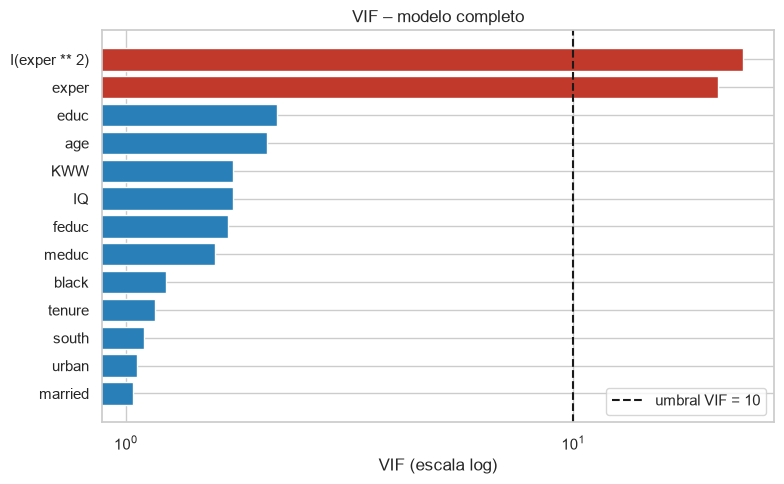

In [8]:
plt.figure(figsize=(8, 5))
colors = ["#c0392b" if v > 10 else "#2980b9" for v in vif_full.VIF]
plt.barh(vif_full.variable, vif_full.VIF, color=colors)
plt.axvline(10, ls="--", color="k", label="umbral VIF = 10")
plt.xscale("log"); plt.xlabel("VIF (escala log)"); plt.legend()
plt.gca().invert_yaxis(); plt.title("VIF – modelo completo")
plt.tight_layout(); plt.show()

### 4.2 Número de condición

In [9]:
X = m_full.model.exog
Xs = X / np.linalg.norm(X, axis=0)          # columnas normalizadas (Belsley, Kuh & Welsch)
cond = np.linalg.cond(Xs)
print(f"Número de condición (X escalada): {cond:.1f}")
print("Regla: < 10 bien | 10–30 moderada | > 30 severa")

Número de condición (X escalada): 77.3
Regla: < 10 bien | 10–30 moderada | > 30 severa


### 4.3 Prueba de Farrar-Glauber (multicolinealidad global)

$H_0$: los regresores son ortogonales (la matriz de correlaciones $R$ es la identidad).

$$\chi^2 = -\left[n - 1 - \frac{2k + 5}{6}\right] \ln |R| \;\sim\; \chi^2_{k(k-1)/2}$$

donde $k$ es el número de regresores (sin la constante) y $|R|$ el determinante de su matriz de correlaciones. Si $|R| \to 0$, la multicolinealidad es severa.

In [10]:
from scipy import stats

def farrar_glauber(model):
    X = pd.DataFrame(model.model.exog, columns=model.model.exog_names).drop(columns="Intercept")
    n, k = X.shape
    R = np.corrcoef(X.values, rowvar=False)
    detR = np.linalg.det(R)
    chi2 = -(n - 1 - (2 * k + 5) / 6) * np.log(detR)
    gl = k * (k - 1) / 2
    return {"|R|": detR, "chi2": chi2, "gl": gl, "valor crítico 5%": stats.chi2.ppf(0.95, gl), "p-valor": stats.chi2.sf(chi2, gl)}

pd.Series(farrar_glauber(m_full))

|R|                   0.0031
chi2               4140.2999
gl                   78.0000
valor crítico 5%     99.6169
p-valor               0.0000
dtype: float64

Como $\chi^2$ supera con mucho el valor crítico, **rechazamos $H_0$**: hay multicolinealidad en el conjunto de regresores. El determinante $|R|$ cercano a cero lo confirma.

### 4.4 Regresiones auxiliares (regla de Klein)

Regresamos cada $x_j$ sobre los demás regresores. **Regla de Klein:** la multicolinealidad es problemática si $R_j^2 > R^2$ del modelo original. Note que $VIF_j = 1/(1-R_j^2)$.

In [11]:
X = pd.DataFrame(m_full.model.exog, columns=m_full.model.exog_names)
aux = []
for v in X.columns.drop("Intercept"):
    r2 = sm.OLS(X[v], X.drop(columns=v)).fit().rsquared
    aux.append({"variable": v, "R² auxiliar": r2, "VIF": 1 / (1 - r2), "¿R²_j > R²?": r2 > m_full.rsquared})
aux = pd.DataFrame(aux).sort_values("R² auxiliar", ascending=False).reset_index(drop=True)
print(f"R² del modelo completo = {m_full.rsquared:.3f}")
aux

R² del modelo completo = 0.264


,variable,R² auxiliar,VIF,¿R²_j > R²?
0,I(exper ** 2),0.9584,24.0103,True
1,exper,0.9526,21.0784,True
2,educ,0.5394,2.1710,True
3,age,0.5166,2.0689,True
4,KWW,0.4250,1.7390,True
5,IQ,0.4229,1.7328,True
6,feduc,0.4100,1.6948,True
7,meduc,0.3691,1.5849,True
8,black,0.1854,1.2276,False
9,tenure,0.1370,1.1588,False


Varios regresores tienen $R_j^2$ mayor que el $R^2$ del modelo (0.26). Esto ocurre porque los salarios son difíciles de predecir, pero los regresores se predicen muy bien entre sí. Según Klein, la multicolinealidad es relevante, y el caso más grave es el de `exper` y `exper²`, con $R_j^2 \approx 0.95$.

### 4.5 Síntomas clásicos
1. **VIF > 20** en `exper` y `exper²`, porque la experiencia y su cuadrado tienen una correlación de 0.975. El número de condición (77) también indica multicolinealidad severa.
2. **Errores estándar inflados**: comparemos el coeficiente de `exper` en el modelo base y en el completo.
3. **Pruebas t individuales débiles, pero la prueba F conjunta es fuerte.**

In [12]:
m_base = smf.ols("lwage ~ educ + exper + I(exper**2)", data=df).fit()

def comparar(models, names, vars_):
    rows = []
    for m, n in zip(models, names):
        for v in vars_:
            if v in m.params:
                rows.append({"modelo": n, "variable": v, "coef": m.params[v], "ee": m.bse[v], "t": m.tvalues[v]})
    return pd.DataFrame(rows).pivot(index="variable", columns="modelo")

comparar([m_base, m_full], ["base", "completo"], ["educ", "exper", "I(exper ** 2)"])

coef              ee                t         
modelo          base completo   base completo    base completo
variable                                                      
I(exper ** 2) 0.0006  -0.0001 0.0007   0.0007  0.9344  -0.2238
educ          0.0783   0.0408 0.0073   0.0089 10.7643   4.5867
exper         0.0087   0.0159 0.0153   0.0146  0.5693   1.0909

In [13]:
# Prueba F conjunta: ¿son exper, exper² y age conjuntamente significativas?
print(m_full.f_test("exper = 0, I(exper ** 2) = 0, age = 0"))
print("\nt individuales:")
print(m_full.tvalues[["exper", "I(exper ** 2)", "age"]])

<F test: F=5.474714791405945, p=0.0010086652221114253, df_denom=708, df_num=3>

t individuales:
exper            1.0909
I(exper ** 2)   -0.2238
age              1.0533
dtype: float64


Las variables de ciclo de vida (`exper`, `exper²`, `age`) son **conjuntamente** significativas, aunque individualmente sus t sean pequeñas. Esa es la firma de la multicolinealidad: los datos saben que *el ciclo de vida importa*, pero no pueden separar el efecto de cada variable.

## 5. Soluciones

### 5.1 Centrar la experiencia
El VIF de `exper` y `exper²` es en buena parte *artificial* (multicolinealidad "no esencial"). Al centrar, $(exper - \bar{exper})$ y su cuadrado dejan de estar casi alineados. **El modelo es exactamente el mismo** (mismo R² y mismas predicciones); solo cambia la interpretación del coeficiente lineal, que pasa a ser el efecto marginal en la experiencia media.

In [14]:
df["exper_c"] = df["exper"] - df["exper"].mean()
print("corr(exper, exper²)     =", round(np.corrcoef(df.exper, df.exper**2)[0, 1], 3))
print("corr(exper_c, exper_c²) =", round(np.corrcoef(df.exper_c, df.exper_c**2)[0, 1], 3))

f_c = f_full.replace("exper + I(exper**2)", "exper_c + I(exper_c**2)")
m_c = smf.ols(f_c, data=df).fit()
print(f"\nR² original = {m_full.rsquared:.6f} | R² centrado = {m_c.rsquared:.6f}")
tabla_vif(m_c)

corr(exper, exper²)     = 0.975
corr(exper_c, exper_c²) = 0.054

R² original = 0.264249 | R² centrado = 0.264249


,variable,VIF
0,educ,2.1710
1,age,2.0689
2,exper_c,2.0110
3,KWW,1.7390
4,IQ,1.7328
5,feduc,1.6948
6,meduc,1.5849
7,black,1.2276
8,I(exper_c ** 2),1.1969
9,tenure,1.1588


### 5.2 Eliminar variables con justificación teórica
- `age` es teóricamente redundante dado `educ` + `exper` (la edad ≈ escolaridad + experiencia + 6), aunque en estos datos su VIF es moderado.
- `IQ` y `KWW` miden lo mismo (habilidad) → usar una sola.
- `meduc` y `feduc` → promediarlas en `peduc` (escolaridad de los padres).

In [15]:
df["peduc"] = (df["meduc"] + df["feduc"]) / 2
f_red = "lwage ~ educ + exper_c + I(exper_c**2) + tenure + IQ + peduc + married + black + south + urban"
m_red = smf.ols(f_red, data=df).fit()
print(m_red.summary().tables[1])
tabla_vif(m_red)

                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           5.2624      0.127     41.390      0.000       5.013       5.512
educ                0.0479      0.008      5.836      0.000       0.032       0.064
exper_c             0.0166      0.004      4.397      0.000       0.009       0.024
I(exper_c ** 2)     0.0002      0.001      0.351      0.726      -0.001       0.001
tenure              0.0086      0.003      2.975      0.003       0.003       0.014
IQ                  0.0038      0.001      3.314      0.001       0.002       0.006
peduc               0.0136      0.006      2.340      0.020       0.002       0.025
married             0.2008      0.043      4.618      0.000       0.115       0.286
black              -0.0909      0.052     -1.752      0.080      -0.193       0.011
south              -0.0663      0.030     -2.191      0.029      -0.126     

,variable,VIF
0,educ,1.8396
1,IQ,1.6050
2,exper_c,1.3968
3,peduc,1.3686
4,black,1.2066
5,tenure,1.1423
6,south,1.0909
7,I(exper_c ** 2),1.0440
8,urban,1.0406
9,married,1.0297


### 5.3 Componentes principales sobre las variables de habilidad y entorno familiar
Combinamos `IQ`, `KWW`, `meduc` y `feduc` en un índice (primer componente principal).

In [16]:
hab = ["IQ", "KWW", "meduc", "feduc"]
Z = StandardScaler().fit_transform(df[hab])
pca = PCA().fit(Z)
print("Varianza explicada por componente:", np.round(pca.explained_variance_ratio_, 3))
print("Cargas del CP1:", dict(zip(hab, np.round(pca.components_[0], 3))))
df["cp1_habilidad"] = pca.transform(Z)[:, 0]

f_pca = "lwage ~ educ + exper_c + I(exper_c**2) + tenure + cp1_habilidad + married + black + south + urban"
m_pca = smf.ols(f_pca, data=df).fit()
print(m_pca.summary().tables[1])

Varianza explicada por componente: [0.523 0.229 0.142 0.106]
Cargas del CP1: {'IQ': np.float64(0.496), 'KWW': np.float64(0.43), 'meduc': np.float64(0.534), 'feduc': np.float64(0.532)}
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           5.8237      0.124     46.850      0.000       5.580       6.068
educ                0.0468      0.008      5.633      0.000       0.030       0.063
exper_c             0.0156      0.004      4.146      0.000       0.008       0.023
I(exper_c ** 2)     0.0002      0.001      0.268      0.789      -0.001       0.001
tenure              0.0083      0.003      2.897      0.004       0.003       0.014
cp1_habilidad       0.0549      0.013      4.370      0.000       0.030       0.080
married             0.1983      0.043      4.565      0.000       0.113       0.284
black              -0.0934      0.052     -1.811      0.071 

### 5.4 Regresión Ridge (extensión)
Ridge minimiza $\sum u_i^2 + \lambda \sum \beta_j^2$: acepta un poco de sesgo a cambio de reducir mucho la varianza de los estimadores.

In [17]:
cols = ["educ", "exper", "tenure", "age", "IQ", "KWW", "meduc", "feduc", "married", "black", "south", "urban"]
Xr = df[cols].assign(exper2=df.exper**2)
sc = StandardScaler().fit(Xr)
ridge = RidgeCV(alphas=np.logspace(-3, 4, 200)).fit(sc.transform(Xr), df.lwage)
print(f"λ óptimo (validación cruzada): {ridge.alpha_:.2f}")

ols_std = sm.OLS(df.lwage, sm.add_constant(sc.transform(Xr))).fit()
pd.DataFrame({"MCO (estand.)": np.asarray(ols_std.params)[1:], "Ridge (estand.)": ridge.coef_}, index=Xr.columns)

λ óptimo (validación cruzada): 98.85


,MCO (estand.),Ridge (estand.)
educ,0.0913,0.0762
exper,0.0677,0.0289
tenure,0.0395,0.0358
age,0.0205,0.0209
IQ,0.0540,0.0515
KWW,0.0219,0.0272
meduc,0.0214,0.0217
feduc,0.0192,0.0218
married,0.0615,0.0535
black,-0.0221,-0.0209


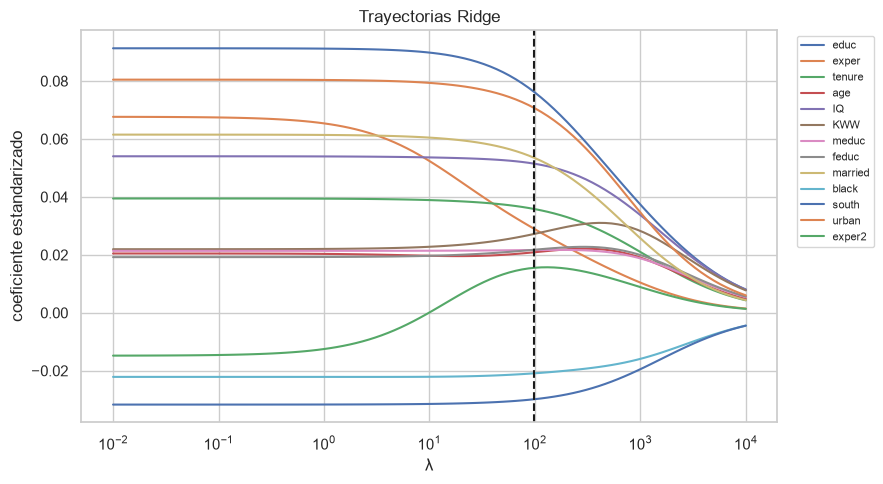

In [18]:
alphas = np.logspace(-2, 4, 100)
from sklearn.linear_model import Ridge
coefs = [Ridge(alpha=a).fit(sc.transform(Xr), df.lwage).coef_ for a in alphas]
plt.figure(figsize=(9, 5))
plt.plot(alphas, coefs)
plt.xscale("log"); plt.axvline(ridge.alpha_, ls="--", color="k")
plt.xlabel("λ"); plt.ylabel("coeficiente estandarizado"); plt.title("Trayectorias Ridge")
plt.legend(Xr.columns, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

## 6. Validación del modelo preferido

Elegimos el **modelo reducido** (5.2) como especificación final: VIF bajos, criterios de información iguales o mejores que el modelo completo y coeficientes fáciles de interpretar. Antes de interpretarlo, verificamos los demás supuestos de MCO.

### 6.1 Heteroscedasticidad: Breusch-Pagan y White
$H_0$: varianza del error constante (homoscedasticidad).

In [19]:
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset
from statsmodels.stats.stattools import jarque_bera

bp = het_breuschpagan(m_red.resid, m_red.model.exog)
wh = het_white(m_red.resid, m_red.model.exog)
pd.DataFrame({"estadístico LM": [bp[0], wh[0]], "p-valor": [bp[1], wh[1]]}, index=["Breusch-Pagan", "White"])

/Users/ximenalara/mincer-multicolinealidad/.venv/lib/python3.13/site-packages/statsmodels/stats/diagnostic.py:1272: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y**2, exog).fit()


,estadístico LM,p-valor
Breusch-Pagan,20.8954,0.0218
White,66.0968,0.2745


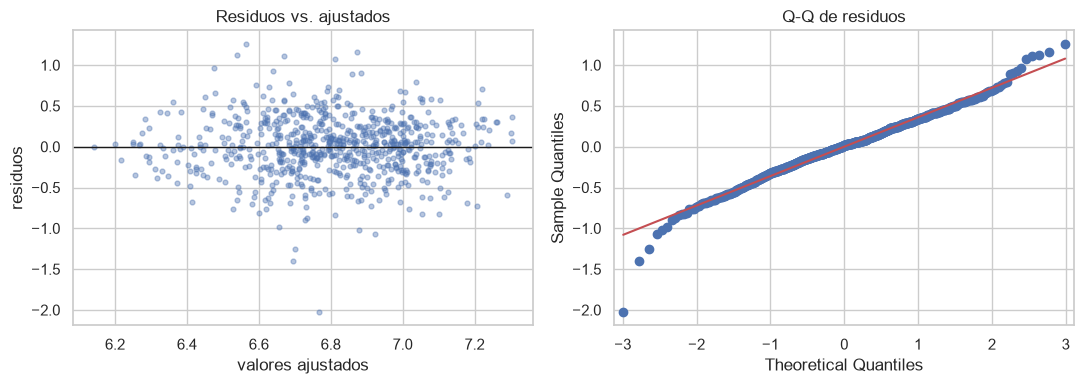

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(m_red.fittedvalues, m_red.resid, alpha=.4, s=12)
ax[0].axhline(0, color="k", lw=1); ax[0].set_xlabel("valores ajustados"); ax[0].set_ylabel("residuos")
ax[0].set_title("Residuos vs. ajustados")
sm.qqplot(m_red.resid, line="s", ax=ax[1]); ax[1].set_title("Q-Q de residuos")
plt.tight_layout(); plt.show()

Las pruebas no coinciden: **Breusch-Pagan rechaza $H_0$ al 5%** (p ≈ 0.02), pero **White no la rechaza** (p ≈ 0.27). White es más general, pero pierde potencia porque incluye muchos términos (cuadrados e interacciones). La advertencia de rango deficiente aparece porque el cuadrado de una variable binaria es igual a la variable misma, y statsmodels lo maneja sin problema. Ante la duda, lo prudente es usar **errores estándar robustos**.

### 6.2 Errores estándar robustos (White / HC1)
Los errores robustos son válidos con o sin heteroscedasticidad. Si las conclusiones no cambian al usarlos, los resultados son sólidos.

In [21]:
m_red_rob = smf.ols(f_red, data=df).fit(cov_type="HC1")
pd.DataFrame({"coef": m_red.params, "ee MCO": m_red.bse, "ee robusto": m_red_rob.bse,
              "p MCO": m_red.pvalues, "p robusto": m_red_rob.pvalues})

,coef,ee MCO,ee robusto,p MCO,p robusto
Intercept,5.2624,0.1271,0.1212,0.0000,0.0000
educ,0.0479,0.0082,0.0087,0.0000,0.0000
exper_c,0.0166,0.0038,0.0038,0.0000,0.0000
I(exper_c ** 2),0.0002,0.0006,0.0007,0.7258,0.7475
tenure,0.0086,0.0029,0.0030,0.0030,0.0042
IQ,0.0038,0.0012,0.0011,0.0010,0.0006
peduc,0.0136,0.0058,0.0053,0.0196,0.0097
married,0.2008,0.0435,0.0431,0.0000,0.0000
black,-0.0909,0.0519,0.0480,0.0802,0.0583
south,-0.0663,0.0302,0.0324,0.0287,0.0409


### 6.3 Especificación: prueba RESET de Ramsey
$H_0$: el modelo está bien especificado (no faltan potencias de los valores ajustados).

In [22]:
reset = linear_reset(m_red, power=3, use_f=True)
print(f"RESET: F = {reset.fvalue:.3f}, p-valor = {reset.pvalue:.4f}")

RESET: F = 0.846, p-valor = 0.4297


Con errores robustos, la significancia de los coeficientes prácticamente no cambia. La única diferencia es que `black` pasa de p ≈ 0.08 a p ≈ 0.06, que sigue siendo significativo solo al 10%. En la prueba RESET, el p-valor es alto, así que **no hay evidencia de mala especificación** de la forma funcional.

### 6.4 Normalidad de los residuos: Jarque-Bera
$H_0$: los residuos son normales. Con $n$ grande, la inferencia es válida asintóticamente aunque se rechace $H_0$.

In [23]:
jb, jb_p, asim, curt = jarque_bera(m_red.resid)
print(f"Jarque-Bera = {jb:.2f}, p-valor = {jb_p:.4f}, asimetría = {asim:.3f}, curtosis = {curt:.3f}")

Jarque-Bera = 113.91, p-valor = 0.0000, asimetría = -0.303, curtosis = 4.849


### 6.5 Interpretación del modelo final
Como la variable dependiente es $\ln(w)$, cada coeficiente $\beta_j \times 100$ es aproximadamente el **cambio porcentual del salario** ante un aumento de una unidad en $x_j$. Para variables binarias, el efecto exacto es $100\,(e^{\beta_j}-1)$.

In [24]:
interp = pd.DataFrame({"coef": m_red.params, "efecto % aprox.": 100 * m_red.params,
                       "efecto % exacto": 100 * (np.exp(m_red.params) - 1), "p-valor": m_red_rob.pvalues}).drop("Intercept")
interp

,coef,efecto % aprox.,efecto % exacto,p-valor
educ,0.0479,4.7892,4.9057,0.0000
exper_c,0.0166,1.6550,1.6688,0.0000
I(exper_c ** 2),0.0002,0.0217,0.0217,0.7475
tenure,0.0086,0.8562,0.8599,0.0042
IQ,0.0038,0.3847,0.3854,0.0006
peduc,0.0136,1.3593,1.3686,0.0097
married,0.2008,20.0814,22.2398,0.0000
black,-0.0909,-9.0927,-8.6916,0.0583
south,-0.0663,-6.6286,-6.4137,0.0409
urban,0.1842,18.4156,20.2204,0.0000


## 7. Comparación de modelos

In [25]:
modelos = {"Base": m_base, "Completo": m_full, "Centrado": m_c, "Reducido": m_red, "PCA": m_pca}
resumen = pd.DataFrame({
    n: {"coef educ": m.params["educ"], "ee educ": m.bse["educ"],
        "R²": m.rsquared, "R² aj.": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic,
        "VIF máx": tabla_vif(m).VIF.max(), "k": int(m.df_model)}
    for n, m in modelos.items()
}).T
resumen

,coef educ,ee educ,R²,R² aj.,AIC,BIC,VIF máx,k
Base,0.0783,0.0073,0.1409,0.1373,691.4907,709.8188,20.3896,3.0000
Completo,0.0408,0.0089,0.2642,0.2507,599.6030,663.7514,24.0103,13.0000
Centrado,0.0408,0.0089,0.2642,0.2507,599.6030,663.7514,2.1710,13.0000
Reducido,0.0479,0.0082,0.2597,0.2492,598.0934,648.4956,1.8396,10.0000
PCA,0.0468,0.0083,0.2600,0.2507,595.7343,641.5545,1.8898,9.0000


## 8. Conclusiones

1. **Multicolinealidad perfecta**: incluir `age`, `educ` y la experiencia potencial `age − educ − 6` hace que $X'X$ sea singular. Los coeficientes no están identificados y la única solución es quitar una variable.
2. **Multicolinealidad imperfecta**: el modelo completo muestra VIF > 20 en `exper` y `exper²`, errores estándar inflados y t individuales pequeñas pese a una F conjunta significativa. **MCO sigue siendo MELI**: la multicolinealidad no sesga los estimadores, solo los vuelve imprecisos.
3. **Centrar** elimina la multicolinealidad "no esencial" entre `exper` y `exper²` sin cambiar el ajuste del modelo.
4. **Eliminar variables redundantes** (`age`) o **combinarlas** (promedio de escolaridad de los padres, CP1 de habilidad) reduce los VIF con poca pérdida de R² y criterios de información iguales o mejores.
5. El **retorno a la educación** se mantiene positivo y significativo en todas las especificaciones, pero baja de ≈7.8% (modelo base) a ≈4–5% al controlar por habilidad y entorno familiar (sesgo por variable omitida), que es otra lección importante.
6. **Ridge** encoge los coeficientes de las variables colineales y estabiliza las estimaciones a cambio de algo de sesgo.
7. **Validación del modelo final:**
   - Hay indicios de heteroscedasticidad (Breusch-Pagan), pero los errores robustos no cambian las conclusiones.
   - La prueba RESET no detecta mala especificación.
   - Los residuos no son normales (Jarque-Bera), pero con n = 722 la inferencia es válida asintóticamente.
8. **Interpretación del modelo final:** un año más de educación eleva el salario ≈ 4.9%, estar casado ≈ 22% y vivir en zona urbana ≈ 20%, manteniendo lo demás constante.

**Referencias**
- Wooldridge, J. M. *Introducción a la econometría: un enfoque moderno*. Cap. 3 y 6.
- Gujarati, D. y Porter, D. *Econometría*. Cap. 10, "Multicolinealidad".
- Mincer, J. (1974). *Schooling, Experience, and Earnings*. NBER.
- Blackburn, M. y Neumark, D. (1992). Datos originales de `wage2`.